# 📘 Notebook 01: Titanic, Who Survived and Why?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 1 · Titanic passengers (891 people, 12 columns)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it like a book, without running anything. To experiment, choose **Runtime → Run all** in Colab: the data downloads in a second and the whole notebook runs in well under a minute. If you rerun it, numbers from the models may differ slightly in the last decimal, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Turn a vague dataset into a **clear question** and a plan to answer it
- Load data straight from a **URL** and take a structured **first look**
- Find and handle **missing values** with a reason for every choice
- Explore **one variable at a time**, then **pairs of variables**, and spot a **confounder**
- **Engineer features** from raw text, such as a person's title from their name
- Build **baseline models** and judge any model against the simplest possible rule

> **Prerequisites:** basic Python and a first contact with pandas (`read_csv`, selecting columns, `groupby`). Charts use matplotlib and seaborn, which are explained as they appear.
>
> 🔭 **Why this notebook matters:** exploratory data analysis (EDA) is the part of data science that decides whether everything after it makes sense. A model trained on data you have not looked at can be accurate for the wrong reasons. The Titanic is the classic first dataset because it is small, real and human: every row is a person, and every pattern has a story you can check against history.

## 0. The question

On 15 April 1912 the RMS Titanic sank on her first voyage. Of roughly 2,200 people on board, about 1,500 died. The dataset holds 891 of the passengers, with what was known about each of them and whether they survived.

**Our question:** *Who survived, and why?* More precisely:

1. Did survival depend on **sex**, **class**, **age** or **family**?
2. Which of these effects are **real**, and which only **look** real because they hide another effect?
3. How well can a simple model **predict** survival, and is it better than common sense?

Every section below answers a piece of this question. Writing the question down first keeps the analysis focused: we look at what helps answer it, not at everything we could compute.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading the data from a URL

The file is the standard Titanic training set, the same one used in the famous Kaggle competition, here read from a public copy on GitHub. `read_csv` accepts a web address exactly like a file name, so no download step is needed.

In [2]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


**What we see.** 891 rows (passengers) and 12 columns. Some columns are numbers (`Age`, `Fare`), some are categories stored as numbers (`Survived` is 0 or 1, `Pclass` is ticket class 1, 2 or 3) and some are free text (`Name`, `Ticket`, `Cabin`). Already in the first five rows we see `NaN` in `Cabin`: the data is not complete.

The columns, briefly: `SibSp` is the number of siblings or spouses on board, `Parch` the number of parents or children, `Embarked` the port where the passenger boarded (C = Cherbourg, Q = Queenstown, S = Southampton).

## 2. First look: types, ranges and missing values

### Intuition first
Before asking questions of the data, ask questions **about** the data: what type is each column, what range does it cover, and what is missing? A column of ages that contains a value of 300 or a column of fares stored as text would break everything later.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000,891.000,891.000,714.000,891.000,891.000,891.000
mean,446.000,0.384,2.309,29.699,0.523,0.382,32.204
std,257.354,0.487,0.836,14.526,1.103,0.806,49.693
min,1.000,0.000,1.000,0.420,0.000,0.000,0.000
25%,223.500,0.000,2.000,20.125,0.000,0.000,7.910
50%,446.000,0.000,3.000,28.000,0.000,0.000,14.454
75%,668.500,1.000,3.000,38.000,1.000,0.000,31.000
max,891.000,1.000,3.000,80.000,8.000,6.000,512.329


**What we see.**
- `Survived` has a mean of **0.384**: since it is 0 or 1, the mean is the survival rate. Only **38.4%** of these passengers survived.
- `Age` runs from **0.42** (a baby of five months) to **80**, with a median of **28**. Its count is 714, not 891: ages are missing.
- `Fare` has a median of **14.45** but a maximum of **512.33**, and its mean (32.20) is more than twice its median. That gap is the signature of a **skewed** variable: a few very expensive tickets pull the mean up.
- `Fare` has a minimum of **0**: some people travelled free (crew members on their way to their posts, or staff of the shipping line).

In [5]:
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "percent": (100 * missing / len(df)).round(1)}).query("missing > 0")

,missing,percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**What we see.** Three columns have gaps, and each needs a different decision:

| Column | Missing | Decision | Reason |
|---|---|---|---|
| `Cabin` | 687 (77.1%) | do not fill; keep only *has a cabin or not* | too much is missing to guess, but **the fact of missing** may itself carry information (Section 5) |
| `Age` | 177 (19.9%) | fill, using information from the name (Section 5) | a fifth of the rows is too many to drop, and age matters for the question |
| `Embarked` | 2 (0.2%) | fill with the most common port | two rows cannot change any conclusion |

There are no duplicate rows. The key lesson: **there is no single rule for missing values**. Each choice depends on how much is missing and on whether the missingness itself means something.

## 3. One variable at a time

We start with the outcome, then each candidate cause on its own.

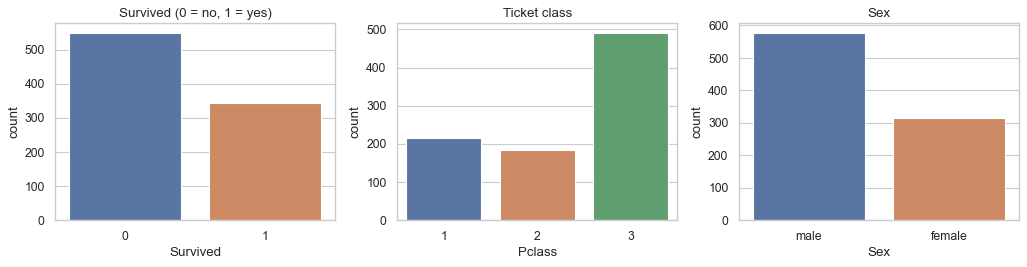

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.countplot(data=df, x="Survived", ax=axes[0]).set_title("Survived (0 = no, 1 = yes)")
sns.countplot(data=df, x="Pclass", ax=axes[1]).set_title("Ticket class")
sns.countplot(data=df, x="Sex", ax=axes[2]).set_title("Sex")
plt.tight_layout()
plt.show()

**What we see.** More passengers died than survived (549 against 342). Third class is by far the largest group, larger than first and second class together, and there are almost twice as many men as women (577 against 314). Keep these sizes in mind: a pattern in a small group is less certain than one in a large group.

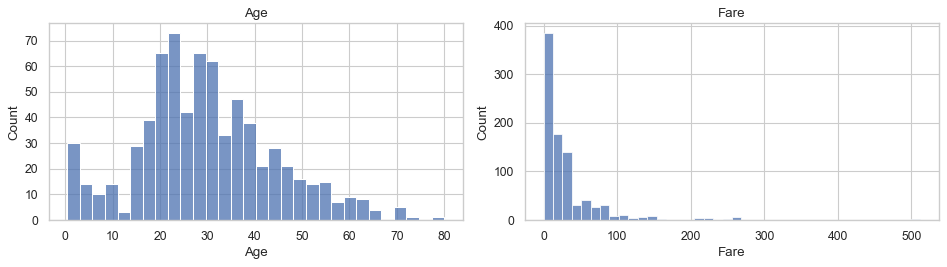

Skewness of Fare: 4.79


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["Age"].dropna(), bins=30, ax=axes[0]).set_title("Age")
sns.histplot(df["Fare"], bins=40, ax=axes[1]).set_title("Fare")
plt.tight_layout()
plt.show()
print("Skewness of Fare:", round(df["Fare"].skew(), 2))

**What we see.** Ages are spread around the twenties and thirties, with a small separate bump of young children. Fares are extremely **right-skewed** (skewness **4.79**; a symmetric variable has 0): most people paid little, and a long thin tail paid a lot. A chart of a skewed variable on a normal scale hides almost everything in one bar, which is why skewed money variables are often viewed on a **log scale**.

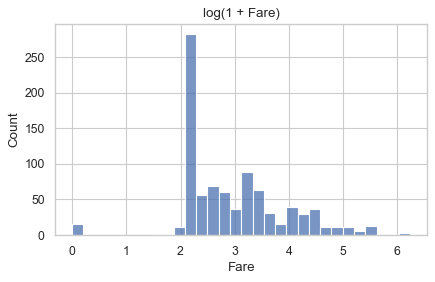

In [9]:
plt.figure(figsize=(6, 3.5))
sns.histplot(np.log1p(df["Fare"]), bins=30).set_title("log(1 + Fare)")
plt.show()

**What we see.** On a log scale the fares spread out into visible groups, which match the three ticket classes. `log1p` (log of 1 + x) is used instead of `log` because some fares are 0, and the log of 0 is undefined.

## 4. Pairs of variables: who survived?

### Intuition first
A survival rate on its own says little. The interesting question is how it **changes** between groups. Because `Survived` is 0 or 1, the mean of `Survived` within a group is that group's survival rate.

In [10]:
by_sex = df.groupby("Sex")["Survived"].agg(rate="mean", passengers="size")
by_class = df.groupby("Pclass")["Survived"].agg(rate="mean", passengers="size")
display(by_sex)
display(by_class)

,rate,passengers
Sex,,
female,0.742,314
male,0.189,577


,rate,passengers
Pclass,,
1,0.630,216
2,0.473,184
3,0.242,491


**What we see.** Two very strong effects:
- **Sex:** **74.2%** of women survived, against **18.9%** of men. This is the "women and children first" rule of the lifeboats, visible in the data.
- **Class:** **63.0%** of first class survived, **47.3%** of second and only **24.2%** of third. First class cabins were closer to the boat deck, and third class passengers had further to go, often through a ship they did not know.

But are these two separate effects, or one effect seen twice? Perhaps first class simply had more women. To find out, we look at both together.

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


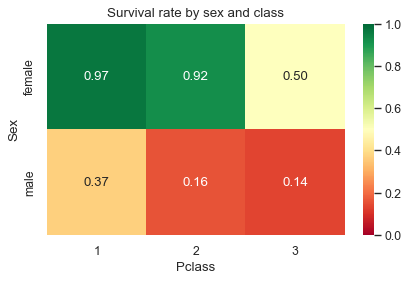

In [11]:
table = df.pivot_table(index="Sex", columns="Pclass", values="Survived")
display(table)
plt.figure(figsize=(6, 3.5))
sns.heatmap(table, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Survival rate by sex and class")
plt.show()

**What we see.** Both effects are real and they **combine**:
- Women in first and second class almost all survived (**96.8%** and **92.1%**). Women in third class had a coin toss (**50.0%**).
- Men in first class survived at **36.9%**, more than twice the rate of men in second (**15.7%**) or third class (**13.5%**).

So sex mattered most, and class mattered **within** each sex. A two-way table like this is one of the most useful tools in EDA, because it separates effects that a one-way table mixes together.

In [12]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 30, 50, 80],
                        labels=["child", "teen", "young adult", "adult", "senior"])
df.groupby("AgeGroup")["Survived"].agg(rate="mean", passengers="size")

,rate,passengers
AgeGroup,,
child,0.580,69
teen,0.429,70
young adult,0.356,270
adult,0.423,241
senior,0.344,64


**What we see.** Children (12 or under) survived at **58.0%**, clearly above every other age group (34% to 43%). Beyond childhood, age makes little difference. Note that this table uses only the 714 passengers whose age is known.

In [13]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df.groupby("FamilySize")["Survived"].agg(rate="mean", passengers="size")

,rate,passengers
FamilySize,,
1,0.304,537
2,0.553,161
3,0.578,102
4,0.724,29
5,0.200,15
6,0.136,22
7,0.333,12
8,0.000,6
11,0.000,7


**What we see.** A curve, not a straight line:
- People travelling **alone** (537 of them) survived at only **30.4%**.
- Small families of **2 to 4** did best, rising to **72.4%** for families of four.
- **Large** families of 5 or more did badly, down to **0%** for the families of 8 and 11.

A relationship that goes up and then down cannot be captured by a single correlation number, which only measures straight-line trends. This is a good reason to always **look** at a variable instead of only computing a coefficient.

### A trap: the port of embarkation

In [14]:
df.groupby("Embarked")["Survived"].agg(rate="mean", passengers="size")

,rate,passengers
Embarked,,
C,0.554,168
Q,0.390,77
S,0.337,644


At first sight the port seems to matter a lot: **55.4%** of those who boarded at **Cherbourg** survived, against **33.7%** at **Southampton**. Did boarding in France save lives? That makes no sense as a cause. Let us look at **who** boarded where.

In [15]:
pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2)

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


**What we see.** **51%** of Cherbourg passengers travelled in first class, against **20%** at Southampton, and **94%** of Queenstown passengers were in third class. The port is not a cause: it is a **proxy for class**. Class is a **confounder**, a hidden variable that drives both the port and survival.

In [16]:
df.pivot_table(index="Embarked", columns="Pclass", values="Survived").round(2)

Pclass,1,2,3
Embarked,,,
C,0.69,0.53,0.38
Q,0.50,0.67,0.38
S,0.58,0.46,0.19


**What we see.** Within the same class, the differences between ports shrink a lot (third class: 38% at Cherbourg and Queenstown, 19% at Southampton; the groups are small, so do not over-read them). Most of the "Cherbourg effect" was a class effect. This is the most important habit in EDA: **when a variable seems to matter, ask what else it is correlated with.**

## 5. Feature engineering: information hidden in text

### Intuition first
The `Name` column looks useless for prediction: every name is different. But every name contains a **title** (Mr, Mrs, Miss, Master...), and a title encodes sex, age and marital status at once. "Master" was the title for boys.

In [17]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"].value_counts()

Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: Title, dtype: int64

In [18]:
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Title"] = "Rare"
df.groupby("Title").agg(rate=("Survived", "mean"), passengers=("Survived", "size"), median_age=("Age", "median"))

,rate,passengers,median_age
Title,,,
Master,0.575,40,3.5
Miss,0.703,185,21.0
Mr,0.157,517,30.0
Mrs,0.794,126,35.0
Rare,0.348,23,48.5


**What we see.** The title separates the passengers sharply: **Mr 15.7%**, **Master 57.5%** (boys, median age **3.5**), **Miss 70.3%**, **Mrs 79.4%**. Unlike `Sex`, the title tells boys apart from men, which is exactly what "women and children first" needs.

The median ages per title are also the best way to **fill the missing ages**: a missing age for a "Master" is far more likely to be 3.5 than the overall median of 28.

In [19]:
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["HasCabin"] = df["Cabin"].notna().astype(int)
print("Missing values left in Age and Embarked:", df[["Age", "Embarked"]].isna().sum().sum())
df.groupby("HasCabin")["Survived"].mean()

Missing values left in Age and Embarked: 0


HasCabin
0    0.300
1    0.667
Name: Survived, dtype: float64

**What we see.** No ages are missing now. And the decision from Section 2 pays off: passengers **with a recorded cabin** survived at **66.7%**, against **30.0%** without. The cabin number itself is mostly unknown, but **whether it was recorded** tells us something, because cabins were recorded mostly for first class passengers.

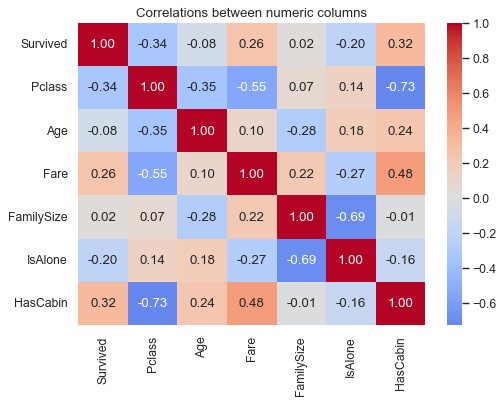

In [20]:
num = df[["Survived", "Pclass", "Age", "Fare", "FamilySize", "IsAlone", "HasCabin"]]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations between numeric columns")
plt.show()

**What we see.** In the `Survived` row: `Pclass` **-0.34** (higher class number, lower survival), `HasCabin` **+0.32**, `Fare` **+0.26**, `IsAlone` **-0.20**. `FamilySize` shows almost **0.02**, even though Section 4 showed it matters a lot: its effect goes up and then down, and a correlation coefficient only sees straight lines. `Pclass`, `Fare` and `HasCabin` are strongly correlated with each other, because all three measure wealth.

## 6. An automatic profile report (optional, Colab)

Libraries such as **ydata-profiling** produce a full report of every column in one line: types, missing values, distributions, correlations and warnings. It is a good **starting point**, never a replacement for the questions we asked above. The cell below installs the library, builds the report and saves it as an HTML file that opens in the browser. It takes about a minute, so it is not run in the saved copy of this notebook.

In [ ]:
%pip install -q ydata-profiling
from ydata_profiling import ProfileReport

raw = pd.read_csv(URL)
report = ProfileReport(raw, title="Titanic: profile report", minimal=True)
report.to_file("titanic_profile.html")
print("Saved titanic_profile.html: open the Files panel on the left and download it.")

## 7. Baseline models: is a model better than common sense?

### Intuition first
Before praising a model, compare it with the **simplest rules** that need no learning at all:
1. **Majority rule:** predict that everyone died.
2. **Sex rule:** predict that women survived and men died.

A model is only interesting if it clearly beats these.

In [21]:
y = df["Survived"]
majority = (y == 0).mean()
sex_rule = ((df["Sex"] == "female").astype(int) == y).mean()
print(f"Majority rule (everyone died): {majority:.3f}")
print(f"Sex rule (women survive):      {sex_rule:.3f}")

Majority rule (everyone died): 0.616
Sex rule (women survive):      0.787


**What we see.** Predicting that everyone died is already right **61.6%** of the time, and the one-line sex rule reaches **78.7%**. Any model below 79% is worse than common sense.

### Formal setup
We now train real models on the engineered features, using **5-fold cross-validation**: the data is split into five parts, each model is trained on four and tested on the fifth, five times, and we report the average. This measures how well the model does on passengers it has **not** seen.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

features = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "IsAlone", "HasCabin", "Embarked", "Title"]
X = pd.get_dummies(df[features], drop_first=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree, depth 3": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Decision tree, no limit": DecisionTreeClassifier(random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
}
results = {name: cross_val_score(model, X, y, cv=cv) for name, model in models.items()}
pd.DataFrame({name: {"mean accuracy": s.mean(), "std": s.std()} for name, s in results.items()}).T

,mean accuracy,std
Logistic regression,0.827,0.010
"Decision tree, depth 3",0.816,0.020
"Decision tree, no limit",0.788,0.034
Random forest,0.833,0.015


**What we see.**
- **Random forest 83.3%** and **logistic regression 82.7%** beat the sex rule by about four points. The features we engineered add real information.
- The small **depth 3 tree** reaches **81.6%** with a handful of yes/no questions, which a person can read.
- The **unlimited tree** is the worst model, at **78.8%**, no better than the sex rule.

In [23]:
full_tree = DecisionTreeClassifier(random_state=42).fit(X, y)
print(f"Unlimited tree, accuracy on its own training data: {full_tree.score(X, y):.3f}")

Unlimited tree, accuracy on its own training data: 0.984


**What we see.** On the passengers it was trained on, the unlimited tree is right **98.4%** of the time, yet on new passengers only **78.8%**. It has **memorised** individual passengers instead of learning general patterns: this is **overfitting**, and it is why we always judge a model on data it has not seen.

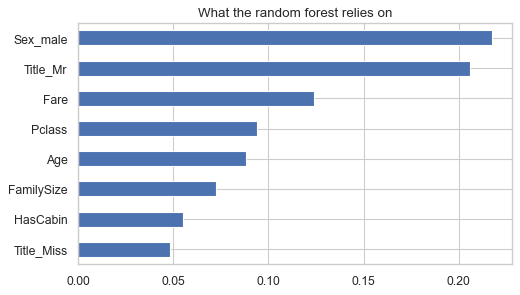

In [24]:
forest = models["Random forest"].fit(X, y)
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 4))
importance.head(8).plot.barh().invert_yaxis()
plt.title("What the random forest relies on")
plt.show()

**What we see.** The forest relies most on `Sex_male` and `Title_Mr`, then `Fare`, `Pclass` and `Age`: the same story the EDA told us, found independently by the model. When the model and the exploration agree, we can trust both a little more. (`Sex_male` and `Title_Mr` overlap heavily, so they share the credit for the same effect.)

## 8. Answer to the question

*Who survived, and why?*

1. **Sex was the strongest factor:** 74% of women survived against 19% of men, in line with the "women and children first" rule.
2. **Class mattered within each sex:** first and second class women almost all survived, third class women only half. First class men survived more than twice as often as other men.
3. **Children** survived more often (58%), and the title "Master" picks out the boys whom `Sex` alone would count as men.
4. **Family size** had a curved effect: travelling alone or in a large family was dangerous, a small family was safest.
5. **The port of embarkation was a false lead:** its effect was mostly class in disguise.
6. A random forest predicts survival correctly **83%** of the time, about four points better than the one-line sex rule, and it relies on the same factors the exploration found.

## 🚀 Going further (for experienced students)

### A. Filling missing values inside cross-validation, with a `Pipeline`
In Section 5 we filled the missing ages using medians computed from **all** passengers, before cross-validation (see the pitfalls below). The professional way is a scikit-learn **`Pipeline`** with a **`ColumnTransformer`**: every preparation step, filling, encoding and scaling, is learned on the training folds only and then applied to the test fold.

In [25]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

raw = pd.read_csv(URL)
raw["Title"] = raw["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip().replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
raw.loc[~raw["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Title"] = "Rare"
raw["FamilySize"] = raw["SibSp"] + raw["Parch"] + 1
raw["HasCabin"] = raw["Cabin"].notna().astype(int)

numeric = ["Age", "Fare", "FamilySize", "HasCabin", "Pclass"]
categorical = ["Sex", "Embarked", "Title"]
prepare = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), categorical),
])
pipe = Pipeline([("prepare", prepare), ("model", LogisticRegression(max_iter=1000))])
scores = cross_val_score(pipe, raw[numeric + categorical], raw["Survived"], cv=cv)
print("Leak-free logistic regression:", round(scores.mean(), 3))

Leak-free logistic regression: 0.831


**What we see.** The leak-free pipeline scores **83.1%**, slightly **above** the 82.7% of Section 7, not below. The leak in our shortcut was tiny, as expected for a dataset this size; the pipeline's value is that the same code stays correct on a dataset where the leak would be large, and that it can be applied unchanged to new passengers.

### B. Groups that travelled together
Popular Kaggle notebooks go one step further: passengers who shared a **ticket number** usually travelled together, as a family or with friends, and often survived or died together. The size of a ticket group is a feature that `SibSp` and `Parch` miss, because friends and servants are not family.

In [26]:
raw["TicketGroup"] = raw.groupby("Ticket")["Ticket"].transform("size")
raw.groupby(raw["TicketGroup"].clip(upper=5))["Survived"].agg(rate="mean", passengers="size")

,rate,passengers
TicketGroup,,
1,0.298,547
2,0.574,188
3,0.698,63
4,0.500,44
5,0.102,49


**What we see.** Passengers on a ticket of their own survived at **29.8%**; groups of 2 and 3 at **57%** and **70%**; groups of 5 or more only **10.2%**. The same curve as family size in Section 4, but now including friends and servants who shared a ticket.

In [27]:
pipe_group = Pipeline([("prepare", ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric + ["TicketGroup"]),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), categorical),
])), ("model", RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42))])
print("Random forest with ticket groups:", round(cross_val_score(pipe_group, raw[numeric + categorical + ["TicketGroup"]], raw["Survived"], cv=cv).mean(), 3))

Random forest with ticket groups: 0.834


**What we see.** With the ticket group added, the random forest reaches **83.4%**, about the same as before. The new feature largely repeats what `FamilySize` already said, a useful lesson: a feature that looks clever in a table does not always add information that the model did not already have. Top Kaggle solutions go further still (survival rates of the *other* members of each group), but those features must be built inside cross-validation, or they leak the answer.

## ⚠️ Common pitfalls

- **Reading a one-way table as a cause.** Cherbourg passengers survived more, but because of their class, not their port. Always check what else a variable is related to.
- **Trusting a correlation coefficient alone.** `FamilySize` has a correlation near zero with survival, yet it matters a lot, because the relationship is curved.
- **Dropping rows with missing values without thinking.** Dropping every row with a missing `Age` would throw away a fifth of the data, and the missing `Cabin` turned out to be informative.
- **Judging a model on its training data.** The unlimited tree scored 98% on data it had seen and 79% on data it had not.
- **A subtle one:** we filled missing ages using medians computed from **all** passengers before cross-validation, so each test fold had a tiny peek at the others. For a dataset this size the effect is negligible, but in a real project, filling should be learned inside each training fold (a scikit-learn `Pipeline` does this).

## ✏️ Exercises

### Exercise 1 (A quick table)
What was the survival rate of **children (age 12 or under) in third class**, and how many such passengers were there? Use the ages **after** filling.

In [28]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
kids = df[(df["Age"] <= 12) & (df["Pclass"] == 3)]
print(len(kids), "passengers, survival rate", round(kids["Survived"].mean(), 3))
```

*Compare with the 58% for all children. Class mattered for children too.*
</details>

### Exercise 2 (Is the fare effect just class?)
`Fare` correlates with survival, but so does `Pclass`. Within **each class**, split passengers into those who paid **above** and **below** the median fare of their class, and compare survival rates. Does fare still matter once class is fixed?

In [29]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
median_fare = df.groupby("Pclass")["Fare"].transform("median")
df["PaidMore"] = (df["Fare"] > median_fare).map({True: "above median", False: "at or below median"})
print(df.pivot_table(index="Pclass", columns="PaidMore", values="Survived").round(3))
```

*In every class, passengers who paid above their class median survived more often (first class 74% against 52%, second 59% against 36%, third 28% against 21%). So fare carries information beyond class: a higher fare often meant a better cabin, or one ticket shared by a whole family.*
</details>

### Exercise 3 (A rule of your own)
Write a rule of at most **three** `if` statements, using any columns, that beats the sex rule (78.7%) on the whole dataset. Hint: what do you know about boys and about women in third class?

In [30]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def rule(row):
    if row["Title"] == "Master":
        return 1
    if row["Sex"] == "female" and row["Pclass"] == 3 and row["FamilySize"] >= 5:
        return 0
    return int(row["Sex"] == "female")

predictions = df.apply(rule, axis=1)
print("Accuracy:", round((predictions == df["Survived"]).mean(), 3))
```

*Saving the boys and sinking the women of large third class families uses two patterns from the EDA. A rule built by looking at all the data is, of course, measured on data it has seen: it would need a fresh test set to be judged fairly, exactly like the unlimited tree.*
</details>

## 🔑 Key takeaways

- Start every analysis with a **written question**; it decides what is worth computing.
- Look at **types, ranges and missing values** first. Each missing column needs its own decision, and missingness can itself be information.
- Explore **one variable**, then **pairs**, then **two-way tables**. Effects that look separate may combine, and effects that look real may be a **confounder** in disguise.
- **Correlation measures only straight lines**: always look at the shape of a relationship.
- **Feature engineering** turns raw text into strong signals, such as the title in a name.
- Judge every model against **simple baselines** and on **unseen data**; a model that only beats itself has learned nothing.

---
**Next:** *Notebook 02: Penguins*, where the question is not *who survived* but *which species is this*, and the tools are distributions, scatter plots and our first look at clusters.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*